# 01 · EDA, nulos y separación train/test

En este notebook describimos el dataset, revisamos su calidad, separamos train y test, analizamos los datos con gráficos, estudiamos los nulos y preparamos las variables que usaremos en los modelos.

**Importante:** el test queda guardado y no lo tocamos hasta la app de Streamlit. Todos los gráficos y las decisiones de imputación se calculan solo con train.

In [1]:
import sys
sys.path.append("..")  # para poder importar src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src.utils import (
    cargar_datos_raw, unknown_a_nan, crear_variables_nuevas,
    ajustar_imputacion, aplicar_imputacion, PROCESSED, RESULTADOS,
)

pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

df_raw = cargar_datos_raw("bank-additional-full.csv")
df_raw.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Descripción del dataset

- **Origen:** *Bank Marketing (with social/economic context)*, UCI Machine Learning Repository. Creado por Moro, Cortez y Rita (2014). Son las llamadas de una campaña de marketing telefónico de un banco portugués (de mayo de 2008 a noviembre de 2010) para vender un depósito a plazo. Incluye cinco indicadores socioeconómicos del Banco de Portugal.
- **Variable objetivo:** `y`, si el cliente contrata el depósito (`yes` / `no`). Es un problema de **clasificación binaria**.
- **Filas y columnas:** las vemos justo debajo.

In [2]:
print(f"Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]} (20 variables + objetivo)")
df_raw.dtypes

Filas: 41188 | Columnas: 21 (20 variables + objetivo)


age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object

In [3]:
pd.concat([df_raw["y"].value_counts(), df_raw["y"].value_counts(normalize=True).round(3)], axis=1)

,count,proportion
y,,
no,36548,0.887
yes,4640,0.113


**Qué vemos:** solo en torno al 11 % de las llamadas termina en contratación.

**Conclusión:** las clases están desbalanceadas. No nos podemos fiar del accuracy (un modelo que diga siempre "no" acertaría el 89 %), y tendremos que comparar los modelos con y sin SMOTE.

## 2. Calidad de los datos

In [4]:
print("Duplicados:", df_raw.duplicated().sum())
print("Nulos reales (NaN):", df_raw.isna().sum().sum())
df_raw.describe().T[["min", "50%", "max"]]

Duplicados: 12
Nulos reales (NaN): 0


,min,50%,max
age,17.000,38.000,98.000
duration,0.000,180.000,4918.000
campaign,1.000,2.000,56.000
pdays,0.000,999.000,999.000
previous,0.000,0.000,7.000
emp.var.rate,-3.400,1.100,1.400
cons.price.idx,92.201,93.749,94.767
cons.conf.idx,-50.800,-41.800,-26.900
euribor3m,0.634,4.857,5.045
nr.employed,4963.600,5191.000,5228.100


In [5]:
print("Edades menores de 18:", (df_raw["age"] < 18).sum(), "| edad máxima:", df_raw["age"].max())
print("Llamadas con duración 0:", (df_raw["duration"] == 0).sum())
print("Clientes con pdays == 999 (no contactados antes):", (df_raw["pdays"] == 999).sum())
print("Máximo de contactos en la campaña:", df_raw["campaign"].max())

Edades menores de 18: 5 | edad máxima: 98
Llamadas con duración 0: 4
Clientes con pdays == 999 (no contactados antes): 39673
Máximo de contactos en la campaña: 56


In [6]:
unknown = (df_raw == "unknown").sum()
pd.DataFrame({"unknown": unknown, "% unknown": (unknown / len(df_raw) * 100).round(1)})[unknown > 0]

,unknown,% unknown
job,330,0.8
marital,80,0.2
education,1731,4.2
default,8597,20.9
housing,990,2.4
loan,990,2.4


**Qué vemos:**
- Hay 12 filas duplicadas y ningún `NaN` real.
- No hay valores imposibles: la edad va de 17 a 98 años (5 clientes tienen 17, los anotamos pero los conservamos por ser tan pocos) y el resto de rangos son razonables. `pdays = 999` no es un error, es el código de "no contactado antes".
- Los nulos están escondidos en la categoría `unknown` de seis variables: `default` (≈21 %), `education` (≈4 %), `housing` y `loan` (≈2,4 %), `job` (≈0,8 %) y `marital` (≈0,2 %).

**Conclusión:** eliminamos los duplicados (son llamadas idénticas en todas las columnas, probablemente registradas dos veces), convertimos `unknown` a `NaN` y quitamos `duration`.

**Por qué quitamos `duration`:** es la duración de la llamada, que solo se conoce después de llamar. Además la propia documentación del dataset avisa de que, si `duration = 0`, `y` es siempre "no". Usarla sería una fuga de datos: el modelo "sabría" el resultado antes de que ocurra y no serviría para decidir a quién llamar.

In [7]:
df = df_raw.drop_duplicates().drop(columns=["duration"])
df = unknown_a_nan(df)
df["y"] = (df["y"] == "yes").astype(int)  # 1 = contrata el depósito
print("Filas tras limpiar:", df.shape[0], "| columnas:", df.shape[1])

Filas tras limpiar: 41176 | columnas: 20


## 3. Tabla de campos

In [8]:
descripcion = {
    "age": "Edad del cliente en años",
    "job": "Tipo de trabajo",
    "marital": "Estado civil (divorced incluye viudos)",
    "education": "Nivel de estudios",
    "default": "Tiene crédito en impago",
    "housing": "Tiene préstamo hipotecario",
    "loan": "Tiene préstamo personal",
    "contact": "Tipo de teléfono del contacto (móvil o fijo)",
    "month": "Mes del último contacto",
    "day_of_week": "Día de la semana del último contacto",
    "duration": "Duración de la última llamada en segundos",
    "campaign": "Nº de contactos en esta campaña con el cliente (incluye el último)",
    "pdays": "Días desde el último contacto de la campaña anterior (999 = no contactado)",
    "previous": "Nº de contactos con el cliente antes de esta campaña",
    "poutcome": "Resultado de la campaña anterior",
    "emp.var.rate": "Variación del empleo (indicador trimestral)",
    "cons.price.idx": "Índice de precios al consumo (mensual)",
    "cons.conf.idx": "Índice de confianza del consumidor (mensual)",
    "euribor3m": "Euríbor a 3 meses (diario)",
    "nr.employed": "Nº de empleados en el país (trimestral)",
    "y": "OBJETIVO: el cliente contrata el depósito (yes/no)",
}

tabla = pd.DataFrame({
    "Campo": df_raw.columns,
    "Qué significa": [descripcion[c] for c in df_raw.columns],
    "Tipo": ["numérica" if pd.api.types.is_numeric_dtype(df_raw[c]) else "categórica" for c in df_raw.columns],
    "% nulos": [round((df_raw[c] == "unknown").mean() * 100, 1) for c in df_raw.columns],
    "¿Se usa?": ["No: fuga de datos" if c == "duration" else "Objetivo" if c == "y" else "Sí" for c in df_raw.columns],
})
tabla

,Campo,Qué significa,Tipo,% nulos,¿Se usa?
0,age,Edad del cliente en años,numérica,0.0,Sí
1,job,Tipo de trabajo,categórica,0.8,Sí
2,marital,Estado civil (divorced incluye viudos),categórica,0.2,Sí
3,education,Nivel de estudios,categórica,4.2,Sí
4,default,Tiene crédito en impago,categórica,20.9,Sí
5,housing,Tiene préstamo hipotecario,categórica,2.4,Sí
6,loan,Tiene préstamo personal,categórica,2.4,Sí
7,contact,Tipo de teléfono del contacto (móvil o fijo),categórica,0.0,Sí
8,month,Mes del último contacto,categórica,0.0,Sí
9,day_of_week,Día de la semana del último contacto,categórica,0.0,Sí


## 4. Separación train/test

Separamos ahora, antes de explorar, para que lo que aprendamos de los datos (gráficos, valores de imputación) venga solo de train. Usamos un 80 % / 20 % con `stratify=y`, para que las dos partes mantengan el mismo porcentaje de contrataciones, y una semilla fija para poder repetirlo.

In [9]:
X = df.drop(columns="y")
y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| % contrata:", round(y_train.mean() * 100, 2))
print("Test: ", X_test.shape, "| % contrata:", round(y_test.mean() * 100, 2))

train = X_train.assign(y=y_train)  # para explorar

Train: (32940, 19) | % contrata: 11.27
Test:  (8236, 19) | % contrata: 11.27


## 5. Análisis de los datos

Todos los gráficos usan solo train. Los guardamos en `resultados/` para el README.

### 5.1 Tasa de contratación por tipo de trabajo (diagrama de barras)

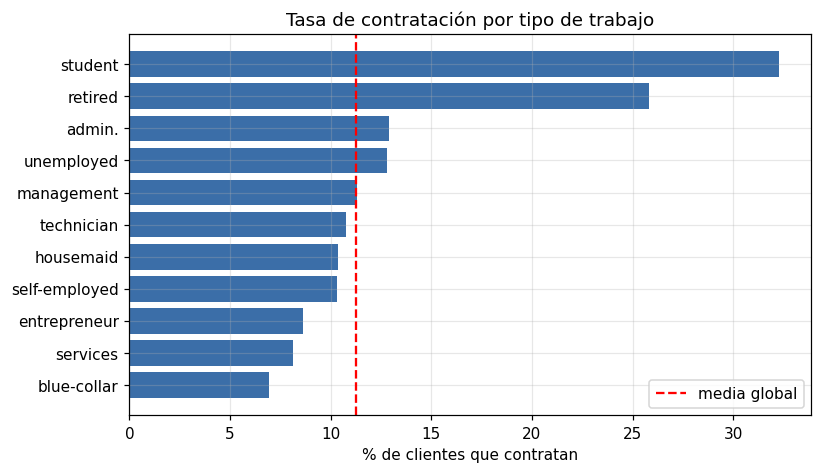

In [10]:
tasa = train.groupby("job")["y"].agg(["mean", "size"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(tasa.index, tasa["mean"] * 100, color="#3B6EA8")
ax.axvline(train["y"].mean() * 100, color="red", ls="--", label="media global")
ax.set_xlabel("% de clientes que contratan")
ax.set_title("Tasa de contratación por tipo de trabajo")
ax.legend()
fig.savefig(RESULTADOS / "eda_tasa_por_trabajo.png", bbox_inches="tight")
plt.show()

**Qué vemos:** los estudiantes (≈32 %) y los jubilados (≈26 %) contratan entre dos y tres veces más que la media (≈11 %), mientras que los trabajadores de `blue-collar` (≈7 %) y de servicios (≈8 %) contratan menos.

**Conclusión:** `job` es una variable con poder para priorizar llamadas. Pero estudiantes y jubilados son pocos clientes (unos 900 y 1.700 en todo el dataset), así que no bastaría con llamar solo a ellos.

### 5.2 Edad: histograma y boxplot

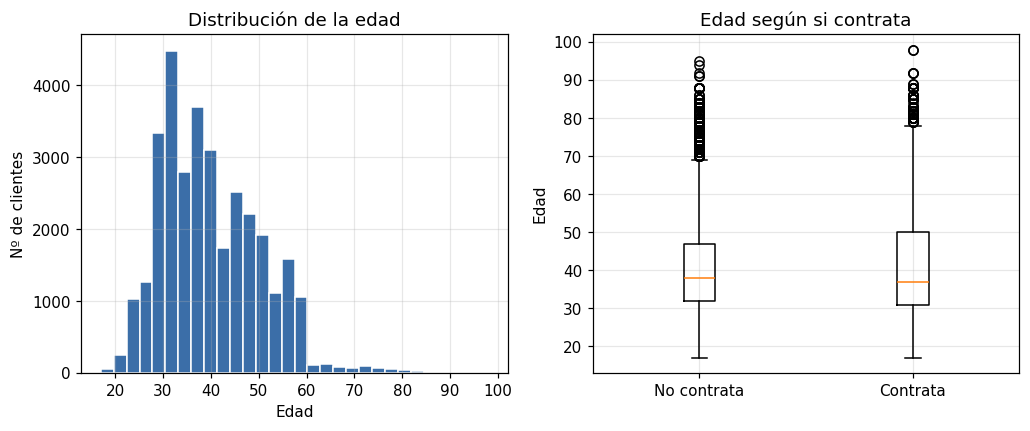

   mean   50%   min   max
y                        
0  39.9  38.0  17.0  95.0
1  41.0  37.0  17.0  98.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(train["age"], bins=30, color="#3B6EA8", edgecolor="white")
axes[0].set_xlabel("Edad")
axes[0].set_ylabel("Nº de clientes")
axes[0].set_title("Distribución de la edad")

axes[1].boxplot([train.loc[train["y"] == 0, "age"], train.loc[train["y"] == 1, "age"]])
axes[1].set_xticklabels(["No contrata", "Contrata"])
axes[1].set_ylabel("Edad")
axes[1].set_title("Edad según si contrata")

fig.savefig(RESULTADOS / "eda_edad.png", bbox_inches="tight")
plt.show()
print(train.groupby("y")["age"].describe()[["mean", "50%", "min", "max"]].round(1))

**Qué vemos:** la edad se concentra entre los 30 y los 50 años, con una cola larga hacia la derecha (valores atípicos a partir de unos 70 años). Las medianas de quienes contratan y quienes no son casi iguales (≈37 y ≈38).

**Conclusión:** la edad por sí sola casi no separa a los que contratan de los que no. Los atípicos son edades reales (clientes mayores), no errores, así que los conservamos. Su efecto sobre el modelo lo controlará el escalado.

### 5.3 Relación entre dos variables: euríbor y nº de empleados (dispersión)

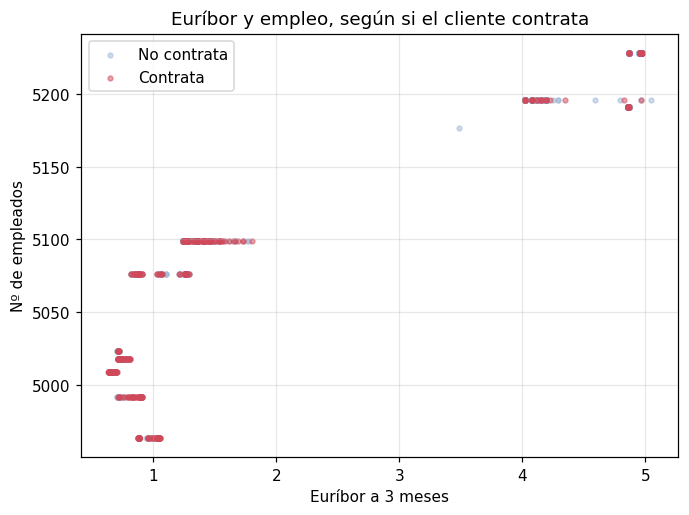

Contratación según euríbor:
            mean   size
euribor3m              
(0, 1]     0.454   3139
(1, 2]     0.156   7685
(2, 6]     0.049  22116


In [12]:
muestra = train.sample(4000, random_state=42)  # muestra para que el gráfico se lea bien
fig, ax = plt.subplots(figsize=(7, 5))
for valor, color, etiqueta in [(0, "#9DB7D5", "No contrata"), (1, "#D1495B", "Contrata")]:
    sub = muestra[muestra["y"] == valor]
    ax.scatter(sub["euribor3m"], sub["nr.employed"], s=10, alpha=0.5, c=color, label=etiqueta)
ax.set_xlabel("Euríbor a 3 meses")
ax.set_ylabel("Nº de empleados")
ax.set_title("Euríbor y empleo, según si el cliente contrata")
ax.legend()
fig.savefig(RESULTADOS / "eda_euribor_empleo.png", bbox_inches="tight")
plt.show()
print("Contratación según euríbor:")
print(train.groupby(pd.cut(train["euribor3m"], [0, 1, 2, 6]), observed=True)["y"].agg(["mean", "size"]).round(3))

**Qué vemos:** las dos variables crecen juntas (correlación ≈0,94). Los puntos rojos (contratan) se concentran donde el euríbor es bajo, por debajo de 1: ahí contrata alrededor del 45 %, frente a menos del 5 % con euríbor alto.

**Conclusión:** el contexto económico pesa mucho en la contratación. No sabemos si es porque con tipos bajos los depósitos resultan más atractivos o porque el banco llamaba a otro tipo de clientes en esos periodos, así que no sacamos una regla de negocio de aquí. Además estas dos variables son casi redundantes entre sí, algo a tener en cuenta con la regresión logística.

### 5.4 Correlaciones (heatmap)

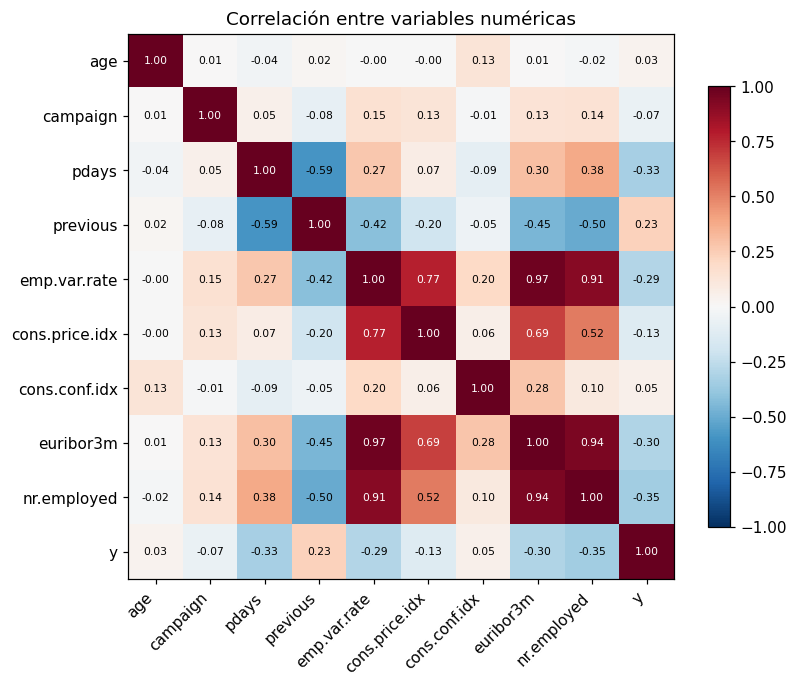

In [13]:
corr = train.select_dtypes("number").corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación entre variables numéricas")
fig.savefig(RESULTADOS / "eda_correlaciones.png", bbox_inches="tight")
plt.show()

**Qué vemos:**
- `emp.var.rate`, `euribor3m` y `nr.employed` están muy correlacionadas entre sí (entre 0,91 y 0,97).
- Con `y`, las más relacionadas son `nr.employed` (≈-0,35), `pdays` (≈-0,33), `euribor3m` (≈-0,30) y `previous` (≈0,23). La edad apenas llega a 0,03.
- La correlación de `pdays` con `y` en gran parte viene del valor 999 ("no contactado").

**Conclusión:** tenemos un bloque de tres variables económicas casi duplicadas. La correlación de `pdays` nos lleva a crear una variable nueva que separe "contactado antes" de "días desde el contacto" (sección 7).

### 5.5 Tasa de contratación por mes (barras)

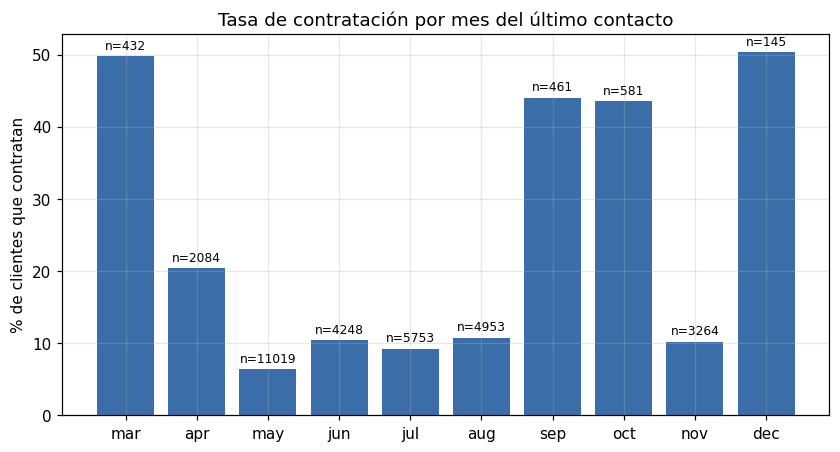

In [14]:
orden = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
por_mes = train.groupby("month")["y"].agg(["mean", "size"]).reindex(orden)

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(por_mes.index, por_mes["mean"] * 100, color="#3B6EA8")
for barra, n in zip(barras, por_mes["size"]):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1, f"n={n}", ha="center", fontsize=8)
ax.set_ylabel("% de clientes que contratan")
ax.set_title("Tasa de contratación por mes del último contacto")
fig.savefig(RESULTADOS / "eda_tasa_por_mes.png", bbox_inches="tight")
plt.show()

**Qué vemos:** en marzo, septiembre, octubre y diciembre contrata en torno al 44-50 %, pero con muy pocas llamadas (entre unas 150 y 600 en cada mes de train). En mayo, el mes con más llamadas (más de 10.000), contrata solo el 6 %.

**Conclusión:** el mes está relacionado con el resultado, pero hay que tener cuidado: los meses "buenos" tienen pocas llamadas y pueden reflejar otra cosa (el contexto económico, o a quién se llamó ese mes) en lugar de un efecto real del mes. Lo mantenemos como variable, pero no sacamos una regla de negocio de aquí.

## 6. Nulos: ¿al azar o con patrón?

Para cada variable con nulos comparamos los clientes con valor nulo con los que no lo tienen: cuántos contratan, su edad media y qué porcentaje fue llamado a un teléfono fijo. Si los nulos fueran al azar, los dos grupos se parecerían.

In [15]:
def perfil_nulos(col):
    """Compara los clientes con nulo en `col` con los que no lo tienen."""
    nulo = train[col].isna()
    return pd.Series({
        "% nulos": nulo.mean() * 100,
        "% contrata (nulo)": train.loc[nulo, "y"].mean() * 100,
        "% contrata (con valor)": train.loc[~nulo, "y"].mean() * 100,
        "edad media (nulo)": train.loc[nulo, "age"].mean(),
        "edad media (con valor)": train.loc[~nulo, "age"].mean(),
        "% tfno. fijo (nulo)": (train.loc[nulo, "contact"] == "telephone").mean() * 100,
        "% tfno. fijo (con valor)": (train.loc[~nulo, "contact"] == "telephone").mean() * 100,
    })

cols_nulos = ["default", "education", "housing", "loan", "job", "marital"]
pd.DataFrame({c: perfil_nulos(c) for c in cols_nulos}).T.round(1)

,% nulos,% contrata (nulo),% contrata (con valor),edad media (nulo),edad media (con valor),% tfno. fijo (nulo),% tfno. fijo (con valor)
default,20.8,5.3,12.8,43.4,39.1,48.6,33.2
education,4.2,14.9,11.1,43.4,39.9,40.3,36.3
housing,2.4,11.7,11.3,40.2,40.0,43.3,36.3
loan,2.4,11.7,11.3,40.2,40.0,43.3,36.3
job,0.8,12.4,11.3,45.2,40.0,48.3,36.3
marital,0.2,16.2,11.3,39.7,40.0,26.5,36.5


In [16]:
print("¿housing y loan son nulos siempre en las mismas filas?", (train["housing"].isna() == train["loan"].isna()).all())
print()
print("% de education nula según job:")
(train.assign(edu_nula=train["education"].isna()).groupby("job")["edu_nula"].mean().mul(100).round(1).sort_values(ascending=False))

¿housing y loan son nulos siempre en las mismas filas? True

% de education nula según job:


job
student          20.0
retired           5.5
blue-collar       5.0
management        4.2
housemaid         4.2
services          3.8
entrepreneur      3.5
technician        3.1
admin.            2.4
self-employed     2.2
unemployed        2.0
Name: edu_nula, dtype: float64

**Qué vemos:**
- **`default` (≈21 %)**: sigue un patrón claro. Quienes tienen `default` nulo contratan mucho menos (≈5 % frente a ≈13 %), son algo mayores y se les llamó más a teléfono fijo. No es al azar.
- **`housing` y `loan` (≈2,4 %)**: son nulos siempre en las mismas filas (probablemente la misma falta de información) y la tasa de contratación es casi igual a la del resto. Parecen al azar.
- **`job` (≈0,8 %) y `marital` (≈0,2 %)**: muy pocos nulos (unos 260 y 65 clientes en train). Contratan igual que el resto (`job`) o con tan pocos casos que la diferencia es ruido (`marital`). En `job` los nulos son algo mayores y más llamados a fijo, pero no cambia la decisión por el tamaño.
- **`education` (≈4 %)**: depende de otra variable: es nula sobre todo en estudiantes y en clientes con `job` desconocido.

**Decisiones:**

| Variable | Tipo de nulo | Cómo lo tratamos | Por qué |
|---|---|---|---|
| `default` | Con patrón | Nueva categoría `desconocido` | Que falte este dato es información en sí misma (contratan ≈5 % frente a ≈13 %). Imputarlo con la moda la taparía |
| `education` | Depende de `job` | Moda de su tipo de trabajo (con la global si `job` también es nulo) | Es nula sobre todo en estudiantes y en `job` desconocido, y el nivel de estudios típico cambia mucho según el trabajo |
| `housing`, `loan`, `job`, `marital` | Al azar (o tan pocos que no importa) | Moda de train | Pocos casos y sin relación con la contratación, así que la moda no distorsiona nada |

Todos los valores de imputación se calculan **solo con train** y se aplican igual a test.

## 7. Variables nuevas

- **`contactado_antes`** (0/1): 1 si `pdays` es distinto de 999. El valor 999 no es una distancia real, es un código, y metido en un modelo (sobre todo en los que escalan) engaña. Por eso pasamos 999 a 0 en `pdays` y guardamos esa información en esta variable. Más abajo comprobamos que importa.
- **`contactos_totales`** = `campaign` + `previous`: cuántas veces hemos hablado con el cliente en total.

No creamos más: el resto de variables ya son informativas por sí mismas y no vemos otra combinación con una razón de negocio clara.

In [17]:
nuevas = crear_variables_nuevas(X_train).assign(y=y_train)
print("% contrata según contactado_antes:")
print(nuevas.groupby("contactado_antes")["y"].agg(["mean", "size"]).round(3))
nuevas[["pdays", "contactado_antes", "contactos_totales"]].describe().T[["min", "mean", "max"]].round(2)

% contrata según contactado_antes:
                   mean   size
contactado_antes              
0                 0.092  31733
1                 0.646   1207


,min,mean,max
pdays,0.0,0.22,27.0
contactado_antes,0.0,0.04,1.0
contactos_totales,1.0,2.74,56.0


**Qué vemos:** los clientes contactados antes contratan en torno al 65 %, unas siete veces más que los que no (≈9 %).

**Conclusión:** `contactado_antes` resume muy bien esa información sin el problema del 999, y será probablemente una de las variables que más pese.

## 8. Imputación y datos procesados

Calculamos los valores de imputación con train, los aplicamos a train y a test, y guardamos los cuatro ficheros en `data/processed/`.

In [18]:
reglas = ajustar_imputacion(X_train)
print("Moda de train:", reglas["moda"])
print("Education por job:", reglas["educacion_por_job"])
print("Education global:", reglas["educacion_global"])

X_train_p = aplicar_imputacion(crear_variables_nuevas(X_train), reglas)
X_test_p = aplicar_imputacion(crear_variables_nuevas(X_test), reglas)

print("\nNulos que quedan -> train:", int(X_train_p.isna().sum().sum()), "| test:", int(X_test_p.isna().sum().sum()))
print("Columnas finales:", list(X_train_p.columns))

Moda de train: {'job': 'admin.', 'marital': 'married', 'housing': 'yes', 'loan': 'no'}
Education por job: {'admin.': 'university.degree', 'blue-collar': 'basic.9y', 'entrepreneur': 'university.degree', 'housemaid': 'basic.4y', 'management': 'university.degree', 'retired': 'basic.4y', 'self-employed': 'university.degree', 'services': 'high.school', 'student': 'high.school', 'technician': 'professional.course', 'unemployed': 'high.school'}
Education global: university.degree

Nulos que quedan -> train: 0 | test: 0
Columnas finales: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contactado_antes', 'contactos_totales']


In [19]:
X_train_p.to_csv(PROCESSED / "X_train.csv", index=False)
X_test_p.to_csv(PROCESSED / "X_test.csv", index=False)
y_train.to_csv(PROCESSED / "y_train.csv", index=False)
y_test.to_csv(PROCESSED / "y_test.csv", index=False)
print("Guardado en data/processed/")

Guardado en data/processed/


## Resumen y siguiente paso

- Dataset: 41.176 clientes tras quitar 12 duplicados, 20 variables y objetivo `y` (≈11 % de contrataciones, clases desbalanceadas).
- Quitamos `duration` por fuga de datos.
- Nulos: `default` como categoría propia, el resto imputado con valores de train.
- Variables nuevas: `contactado_antes` y `contactos_totales`.

**Siguiente paso:** montar el pipeline de scikit-learn (`StandardScaler` + `OneHotEncoder`) en `src/utils.py`, que usarán todos los modelos, y entrenar el primero registrándolo en MLflow.